# METR-LA Dataset Inspection and Exploratory Data Analysis

**UrbanFlow AI - Task 02**

This notebook explores the real METR-LA traffic-speed dataset and checks that it is suitable for later forecasting experiments. The analysis is reproducible and does not change the source data. In particular, zero readings are kept exactly as recorded, and no values are filled, normalized, split into training and test sets, or converted into forecasting windows. No model is trained here. Speeds are reported in miles per hour (mph), following the METR-LA benchmark convention.


## 0. Reproducible setup and provenance

The main files were downloaded from Zenodo record 5724362. Each file is identified by a SHA-256 hash, which acts like a digital fingerprint: if the file changes, its hash should also change. The graph is stored as a Python pickle. Because loading an untrusted pickle can execute code, this notebook loads only the named project file that was obtained from the documented source. The copied `graph_sensor_ids.txt` file comes from the local DCRNN reference repository and remains in the Git-ignored raw-data directory.


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# Allow the notebook to run from either the repository root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'data' / 'raw' / 'metr-la').exists():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'raw' / 'metr-la').exists():
    raise FileNotFoundError('Run this notebook from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT))

from src.data.inspection import (
    EXPECTED_SENSORS, EXPECTED_TIME_STEPS, inspect_timestamps,
    load_graph_bundle, load_speed_data, longest_true_run,
    read_sensor_ids, validate_graph_alignment,
)

DATA_DIR = ROOT / 'data' / 'raw' / 'metr-la'
CSV_PATH = DATA_DIR / 'METR-LA.csv'
GRAPH_PATH = DATA_DIR / 'adj_mx_METR-LA.pkl'
IDS_PATH = DATA_DIR / 'graph_sensor_ids.txt'

def sha256(path):
    # Read in blocks so even the large CSV does not need to be loaded into memory at once.
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

provenance = pd.DataFrame([
    {'file': p.name, 'bytes': p.stat().st_size, 'sha256': sha256(p)}
    for p in (CSV_PATH, GRAPH_PATH, IDS_PATH)
])
display(provenance)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 20)


,file,bytes,sha256
0,METR-LA.csv,72467662,8d67a35472db1719d7d4be851f2bf64cb21d9c52577c8a...
1,adj_mx_METR-LA.pkl,680459,a35687c6e15aa228dc45027b0ed2a0ea0f4ec78f573deb...
2,graph_sensor_ids.txt,1448,3ba026caa2e6263ab0ea54b0fa1b125dbfa7216544cd05...


## 1. Dataset overview

Each row represents one observation time, and each sensor column contains the speed recorded at that location. The first CSV column is therefore read as the timestamp index, while the remaining column names are treated as sensor IDs. The checks below confirm the expected 34,272 five-minute observations and 207 sensors instead of assuming that the downloaded file is correct.

The five-minute sampling interval also explains the window sizes planned for later tasks. Twelve consecutive input steps represent the previous 60 minutes (`12 × 5 = 60`), and twelve output steps represent the next 60 minutes. The +15, +30, and +60 minute evaluation horizons will therefore correspond to output steps 3, 6, and 12. This notebook only verifies the sampling interval; it does not create forecasting windows.


In [2]:
speeds = load_speed_data(CSV_PATH)
timestamp_report = inspect_timestamps(speeds.index)
overview = pd.Series({
    'time_steps': speeds.shape[0],
    'sensors': speeds.shape[1],
    'start': timestamp_report.start,
    'end': timestamp_report.end,
    'index_dtype': str(speeds.index.dtype),
    'unique_sensor_ids': speeds.columns.nunique(),
    'numeric_columns': int(speeds.dtypes.apply(pd.api.types.is_numeric_dtype).sum()),
})
display(overview.to_frame('value'))
display(speeds.iloc[:3, :8])
display(speeds.dtypes.value_counts().rename_axis('dtype').to_frame('column_count'))
assert speeds.shape == (EXPECTED_TIME_STEPS, EXPECTED_SENSORS)
display(Markdown(
    f'**Interpretation.** The file contains **{speeds.shape[0]:,} time steps** and '
    f'**{speeds.shape[1]} unique sensor columns**, exactly matching the expected dimensions. '
    f'The observed period is **{timestamp_report.start} to {timestamp_report.end}**.'
))


,value
time_steps,34272
sensors,207
start,2012-03-01 00:00:00
end,2012-06-27 23:55:00
index_dtype,datetime64[us]
unique_sensor_ids,207
numeric_columns,207


,773869,767541,767542,717447,717446,717445,773062,767620
timestamp,,,,,,,,
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250


,column_count
dtype,
float64,207


**Interpretation.** The file contains **34,272 time steps** and **207 unique sensor columns**, exactly matching the expected dimensions. The observed period is **2012-03-01 00:00:00 to 2012-06-27 23:55:00**.

In [3]:
interval_table = timestamp_report.interval_counts.rename('count').to_frame()
interval_table.index = interval_table.index.astype(str)
display(interval_table)
cadence_summary = pd.Series({
    'duplicate_timestamps': timestamp_report.duplicate_count,
    'non_increasing_intervals': timestamp_report.non_increasing_count,
    'irregular_intervals_not_5_minutes': timestamp_report.irregular_interval_count,
})
display(cadence_summary.to_frame('count'))
display(Markdown(
    '**Interpretation.** Timestamps are strictly increasing, unique, and uniformly spaced at '
    '**5 minutes**; no missing or irregular timestamp intervals were found.'
))

,count
timestamp,
0 days 00:05:00,34271


,count
duplicate_timestamps,0
non_increasing_intervals,0
irregular_intervals_not_5_minutes,0


**Interpretation.** Timestamps are strictly increasing, unique, and uniformly spaced at **5 minutes**; no missing or irregular timestamp intervals were found.

## 2. Data quality

Missing values and exact zeros are counted separately because they are not automatically the same thing. A zero could mean stopped traffic, a sensor problem, or a value used by the data provider to represent an unavailable reading. The dataset does not tell us which explanation applies in every case, so this notebook keeps all zeros unchanged. A **zero-value run** means several consecutive five-minute readings equal to zero. Long runs, especially when many sensors are zero at the same time, may indicate a data-quality problem that must be handled carefully in Task 03.


In [4]:
missing_by_sensor = speeds.isna().sum()
zero_by_sensor = speeds.eq(0).sum()
negative_by_sensor = speeds.lt(0).sum()
# Count how many sensors report zero at each five-minute timestamp.
zero_sensors_per_timestamp = speeds.eq(0).sum(axis=1)
all_sensor_zero_mask = zero_sensors_per_timestamp.eq(speeds.shape[1])
quality_summary = pd.Series({
    'total_cells': speeds.size,
    'missing_cells': int(missing_by_sensor.sum()),
    'zero_cells': int(zero_by_sensor.sum()),
    'zero_percent': 100 * zero_by_sensor.sum() / speeds.size,
    'negative_cells': int(negative_by_sensor.sum()),
    'sensors_with_any_zero': int((zero_by_sensor > 0).sum()),
    'sensors_with_any_missing': int((missing_by_sensor > 0).sum()),
    'timestamps_with_any_zero': int(zero_sensors_per_timestamp.gt(0).sum()),
    'timestamps_with_all_sensors_zero': int(all_sensor_zero_mask.sum()),
    'longest_all_sensor_zero_run_steps': longest_true_run(all_sensor_zero_mask),
})
display(quality_summary.to_frame('value'))

sensor_quality = pd.DataFrame({
    'missing_count': missing_by_sensor,
    'zero_count': zero_by_sensor,
    'zero_percent': 100 * zero_by_sensor / len(speeds),
    # A run is a sequence of consecutive five-minute zero readings for one sensor.
    'longest_zero_run_steps': [longest_true_run(speeds[c].eq(0)) for c in speeds],
    'min_mph': speeds.min(),
    'mean_mph': speeds.mean(),
    'std_mph': speeds.std(),
    'max_mph': speeds.max(),
}).sort_values(['zero_percent', 'longest_zero_run_steps'], ascending=False)
display(sensor_quality.head(15))
display(Markdown(
    f'**Interpretation.** There are **{int(missing_by_sensor.sum()):,} explicit NaN cells** and '
    f'**{int(zero_by_sensor.sum()):,} exact-zero readings ({100 * zero_by_sensor.sum() / speeds.size:.3f}% of all readings)**. '
    f'Zeros occur in **{int((zero_by_sensor > 0).sum())} of {speeds.shape[1]} sensors**. '
    f'Notably, **{int(all_sensor_zero_mask.sum()):,} timestamps have zero at all sensors**, with a longest run of '
    f'**{longest_true_run(all_sensor_zero_mask)} steps ({longest_true_run(all_sensor_zero_mask) * 5 / 60:.2f} hours)**. '
    'They are retained as observed values; these synchronized runs require an explicit, documented policy later.'
))


,value
total_cells,7.094304e+06
missing_cells,0.000000e+00
zero_cells,5.753020e+05
zero_percent,8.109351e+00
negative_cells,0.000000e+00
sensors_with_any_zero,2.070000e+02
sensors_with_any_missing,0.000000e+00
timestamps_with_any_zero,2.906600e+04
timestamps_with_all_sensors_zero,2.148000e+03
longest_all_sensor_zero_run_steps,3.810000e+02


,missing_count,zero_count,zero_percent,longest_zero_run_steps,min_mph,mean_mph,std_mph,max_mph
718076,0,6890,20.103875,875,0.0,53.759408,27.064229,70.0
716939,0,6464,18.860878,905,0.0,42.714148,25.127354,70.0
760987,0,5532,16.141457,1014,0.0,54.618180,25.068959,70.0
716955,0,5374,15.680439,857,0.0,32.738368,17.721576,70.0
769418,0,5349,15.607493,422,0.0,48.431374,22.030828,70.0
769405,0,5346,15.598739,422,0.0,40.435995,18.889680,70.0
717481,0,5163,15.064776,390,0.0,55.901745,25.846370,70.0
717510,0,5156,15.044351,381,0.0,49.302834,22.066370,70.0
717513,0,4819,14.061041,381,0.0,51.513639,22.265961,70.0
717576,0,4675,13.640873,1118,0.0,55.393959,23.042098,70.0


**Interpretation.** There are **0 explicit NaN cells** and **575,302 exact-zero readings (8.109% of all readings)**. Zeros occur in **207 of 207 sensors**. Notably, **2,148 timestamps have zero at all sensors**, with a longest run of **381 steps (31.75 hours)**. They are retained as observed values; these synchronized runs require an explicit, documented policy later.

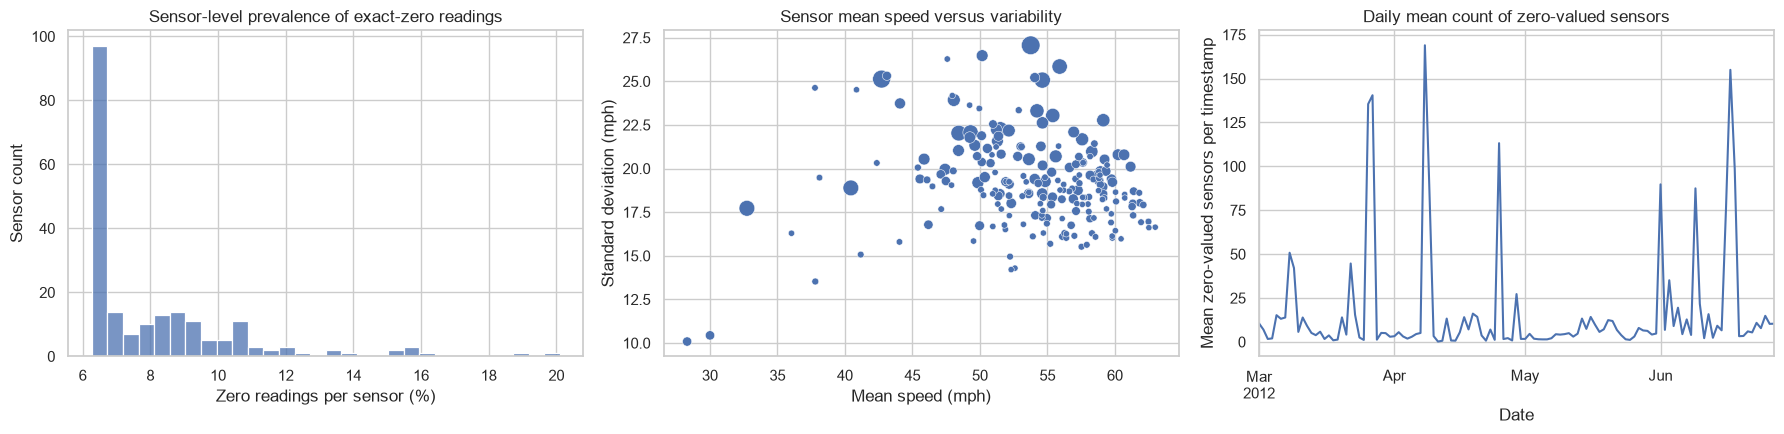

**What the charts show and why it matters.** The first chart shows that zero readings are not equally common at every sensor. The second compares each sensor's average speed with its variability; large zero counts can make a sensor appear more variable than normal traffic alone would suggest. The third chart shows how many sensors are zero over time and reveals periods when zeros occur together. Forecasting models could learn these data-quality patterns instead of real traffic behaviour, so later preprocessing must examine both individual sensors and shared time periods.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(sensor_quality['zero_percent'], bins=30, ax=axes[0])
axes[0].set(title='Sensor-level prevalence of exact-zero readings', xlabel='Zero readings per sensor (%)', ylabel='Sensor count')
sns.scatterplot(data=sensor_quality, x='mean_mph', y='std_mph', size='zero_percent', sizes=(20, 180), ax=axes[1], legend=False)
axes[1].set(title='Sensor mean speed versus variability', xlabel='Mean speed (mph)', ylabel='Standard deviation (mph)')
zero_sensors_per_timestamp.resample('1D').mean().plot(ax=axes[2])
axes[2].set(title='Daily mean count of zero-valued sensors', xlabel='Date', ylabel='Mean zero-valued sensors per timestamp')
plt.tight_layout()
plt.show()
display(Markdown(
    '**What the charts show and why it matters.** The first chart shows that zero readings are not equally common at every sensor. '
    "The second compares each sensor's average speed with its variability; large zero counts can make a sensor appear more variable than normal traffic alone would suggest. "
    'The third chart shows how many sensors are zero over time and reveals periods when zeros occur together. Forecasting models could learn these data-quality patterns instead of real traffic behaviour, so later preprocessing must examine both individual sensors and shared time periods.'
))


## 3. Traffic-speed analysis

All plots in this section use the recorded values, including zeros. The overall distribution describes the range and typical level of traffic speeds, while sensor-level summaries show whether different locations behave differently. The hourly and day-of-week profiles use the complete dataset only for exploration. They are not trained features or performance estimates; later modelling must calculate any learned statistics from the training period only.


,value
minimum_mph,0.000000
p01_mph,0.000000
median_mph,62.444444
mean_mph,53.719021
p99_mph,69.666667
maximum_mph,70.000000
standard_deviation_mph,20.261431


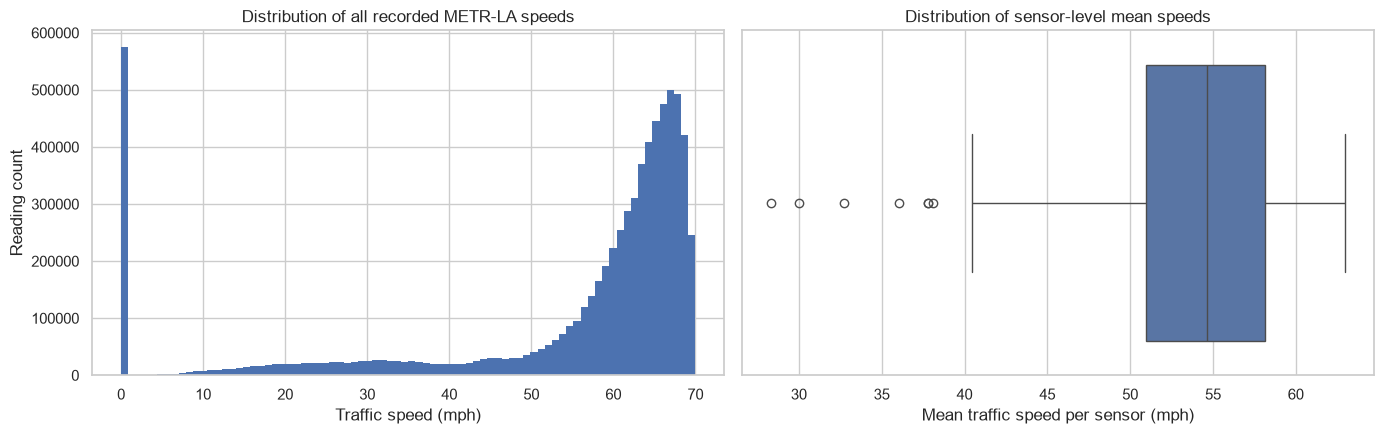

**What the charts show and why it matters.** Recorded speeds range from **0.0 to 70.0 mph**; the overall median is **62.44 mph** and mean is **53.72 mph**. The histogram shows many readings near free-flow speed and a long lower-speed tail that includes congestion and zero readings. The box plot shows how average speed differs across sensor locations. A forecasting model should therefore be evaluated in both normal and slow-traffic conditions rather than only by one overall average.

In [6]:
values = speeds.to_numpy().ravel()
overall_stats = pd.Series({
    'minimum_mph': np.nanmin(values), 'p01_mph': np.nanpercentile(values, 1),
    'median_mph': np.nanmedian(values), 'mean_mph': np.nanmean(values),
    'p99_mph': np.nanpercentile(values, 99), 'maximum_mph': np.nanmax(values),
    'standard_deviation_mph': np.nanstd(values),
})
display(overall_stats.to_frame('value'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# Bin every non-missing reading first; drawing precomputed bins is faster than asking the plotting library to process millions of points.
hist_counts, hist_edges = np.histogram(values[~np.isnan(values)], bins=80)
axes[0].stairs(hist_counts, hist_edges, fill=True)
axes[0].set(title='Distribution of all recorded METR-LA speeds', xlabel='Traffic speed (mph)', ylabel='Reading count')
sns.boxplot(x=speeds.mean(), ax=axes[1])
axes[1].set(title='Distribution of sensor-level mean speeds', xlabel='Mean traffic speed per sensor (mph)')
plt.tight_layout()
plt.show()
display(Markdown(
    f'**What the charts show and why it matters.** Recorded speeds range from **{np.nanmin(values):.1f} to {np.nanmax(values):.1f} mph**; '
    f'the overall median is **{np.nanmedian(values):.2f} mph** and mean is **{np.nanmean(values):.2f} mph**. '
    'The histogram shows many readings near free-flow speed and a long lower-speed tail that includes congestion and zero readings. '
    'The box plot shows how average speed differs across sensor locations. A forecasting model should therefore be evaluated in both normal and slow-traffic conditions rather than only by one overall average.'
))

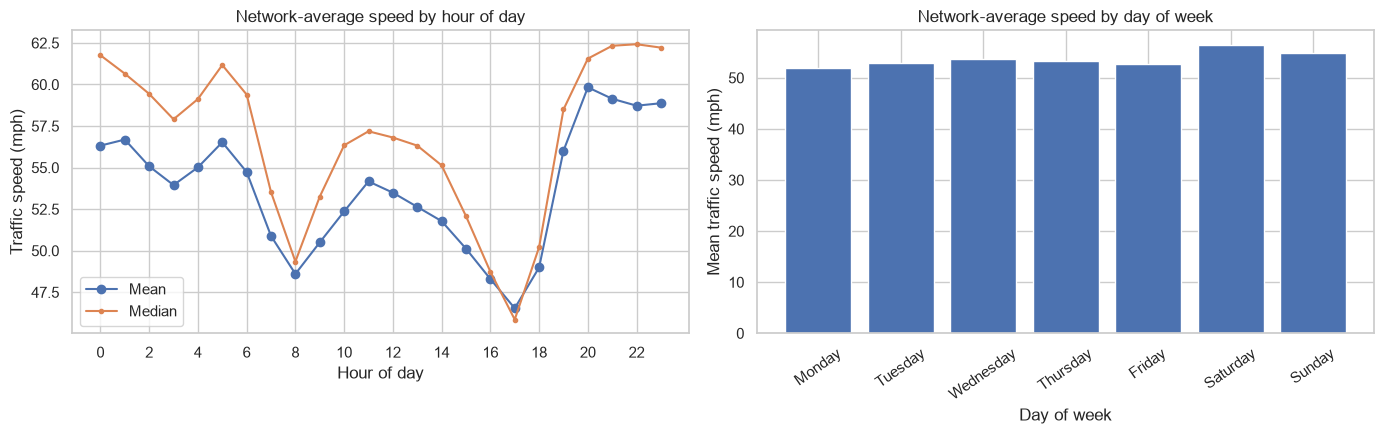

,mean,median,std
timestamp,,,
0,56.322,61.760,17.831
1,56.687,60.653,15.705
2,55.079,59.436,16.549
3,53.947,57.907,16.179
4,55.014,59.125,15.479
5,56.526,61.170,16.236
6,54.735,59.394,16.949
7,50.886,53.525,16.101
8,48.602,49.346,16.256


,mean,median,std
Monday,52.004,58.626,18.058
Tuesday,52.909,56.819,13.863
Wednesday,53.730,57.103,12.069
Thursday,53.360,56.895,11.720
Friday,52.730,56.637,13.176
Saturday,56.445,60.245,13.297
Sunday,54.856,62.518,20.119


**What the charts show and why it matters.** The hourly chart summarizes the typical daily traffic cycle across the network. The lowest hourly network mean occurs at **17:00** (46.53 mph), while **Saturday** has the highest day-level mean (56.44 mph). The day-of-week chart shows broader differences between weekdays and weekends. These repeated patterns can help a forecasting model distinguish expected rush-hour slowdowns from unusual changes, but any fitted encoding must respect chronological splits.

In [7]:
# Average across all sensors at each timestamp to obtain a network-wide speed series.
overall_series = speeds.mean(axis=1)
hourly = overall_series.groupby(overall_series.index.hour).agg(['mean', 'median', 'std'])
daily = overall_series.groupby(overall_series.index.day_of_week).agg(['mean', 'median', 'std'])
daily.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hourly.index, hourly['mean'], marker='o', label='Mean')
axes[0].plot(hourly.index, hourly['median'], marker='.', label='Median')
axes[0].set(title='Network-average speed by hour of day', xlabel='Hour of day', ylabel='Traffic speed (mph)', xticks=range(0, 24, 2))
axes[0].legend()
axes[1].bar(daily.index, daily['mean'])
axes[1].set(title='Network-average speed by day of week', xlabel='Day of week', ylabel='Mean traffic speed (mph)')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()
display(hourly.round(3))
display(daily.round(3))
display(Markdown(
    f'**What the charts show and why it matters.** The hourly chart summarizes the typical daily traffic cycle across the network. The lowest hourly network mean occurs at **{int(hourly["mean"].idxmin()):02d}:00** '
    f'({hourly["mean"].min():.2f} mph), while **{daily["mean"].idxmax()}** has the highest day-level mean '
    f'({daily["mean"].max():.2f} mph). The day-of-week chart shows broader differences between weekdays and weekends. These repeated patterns can help a forecasting model distinguish expected rush-hour slowdowns from unusual changes, '
    'but any fitted encoding must respect chronological splits.'
))


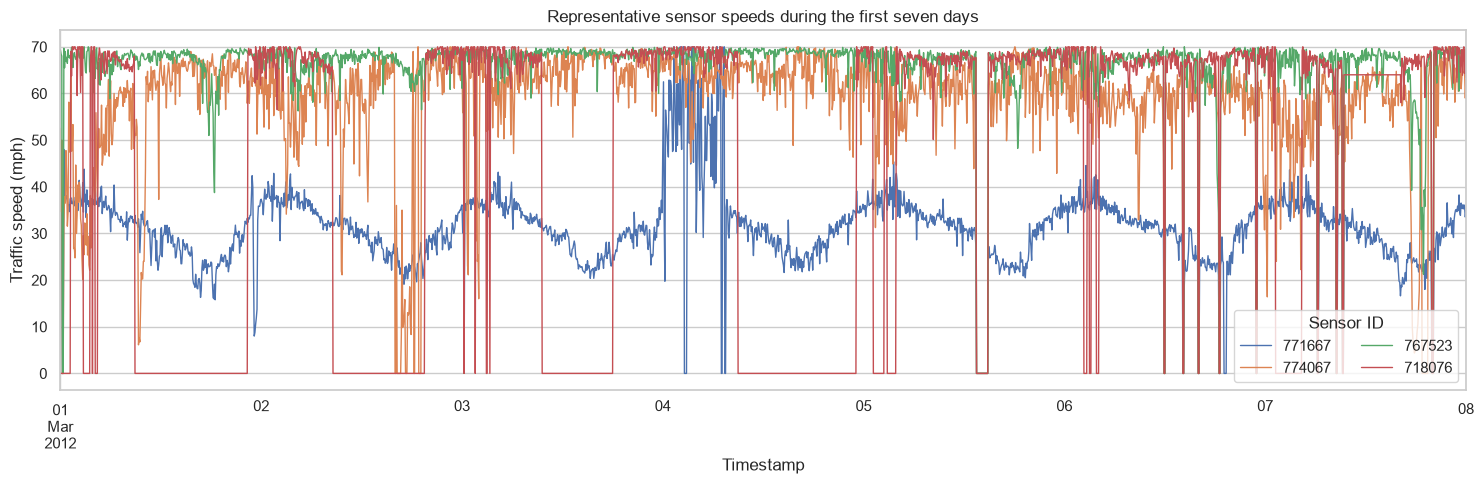

,missing_count,zero_count,zero_percent,longest_zero_run_steps,min_mph,mean_mph,std_mph,max_mph
771667,0,2867,8.365430,381,0.0,28.310130,10.084643,70.0
774067,0,3292,9.605509,381,0.0,54.643000,20.178007,70.0
767523,0,2148,6.267507,381,0.0,62.985336,16.639751,70.0
718076,0,6890,20.103875,875,0.0,53.759408,27.064229,70.0


**What the chart shows and why it matters.** The selected sensors represent low, middle, and high average speeds, together with the sensor that has the largest percentage of zeros. Their lines differ in level, variability, and zero episodes, showing that one network-wide score can hide poor performance at particular locations. Later evaluation should therefore include sensor-level errors as well as overall metrics.

In [8]:
# Select sensors with low, middle, and high mean speeds, plus the sensor with the most zeros.
ranked_means = speeds.mean().sort_values()
representative = list(dict.fromkeys([
    ranked_means.index[0], ranked_means.index[len(ranked_means) // 2], ranked_means.index[-1],
    sensor_quality.index[0],
]))
week = speeds.loc[speeds.index[0]: speeds.index[0] + pd.Timedelta(days=7), representative]
ax = week.plot(figsize=(15, 5), linewidth=1)
ax.set(title='Representative sensor speeds during the first seven days', xlabel='Timestamp', ylabel='Traffic speed (mph)')
ax.legend(title='Sensor ID', ncol=2)
plt.tight_layout()
plt.show()
display(sensor_quality.loc[representative])
display(Markdown(
    '**What the chart shows and why it matters.** The selected sensors represent low, middle, and high average speeds, together with the sensor that has the largest percentage of zeros. '
    'Their lines differ in level, variability, and zero episodes, showing that one network-wide score can hide poor performance at particular locations. Later evaluation should therefore include sensor-level errors as well as overall metrics.'
))


## 4. Graph inspection and sensor ordering

The road network is represented as a graph: sensors are **nodes**, and a connection between two sensors is an **edge**. An **adjacency matrix** stores these connections in a table. Row *i* and column *j* contain the weight of the connection from sensor *i* to sensor *j*; a zero means that the supplied graph has no direct edge in that direction.

**Sensor alignment** means checking that position 0, position 1, and so on refer to the same sensor in the CSV, the graph metadata, and the adjacency matrix. A mismatch would attach traffic readings to the wrong road locations. The DCRNN-format pickle contains `(sensor_ids, sensor_id_to_index, adjacency)`, so alignment is checked using ID membership, ID order, the ID-to-index mapping, and the copied DCRNN reference list.

**Graph connectivity** describes whether sensors can be reached through one or more edges. In a directed graph, a weakly connected component ignores edge direction, while a strongly connected component requires directed paths in both directions. These checks describe the supplied graph structure; they do not prove that one road causally affects another.


In [9]:
graph = load_graph_bundle(GRAPH_PATH)
reference_ids = read_sensor_ids(IDS_PATH)
alignment = validate_graph_alignment(speeds.columns, graph, reference_ids)
display(pd.Series(alignment).to_frame('value'))
A = graph.adjacency
# Remove self-connections temporarily so edge and connectivity summaries describe links between different sensors.
off_diagonal = A.copy()
np.fill_diagonal(off_diagonal, 0)
positive_weights = off_diagonal[off_diagonal > 0]
n = A.shape[0]
# Weak connectivity ignores direction; strong connectivity follows the directed edges.
weak_components = connected_components(csr_matrix(off_diagonal), directed=True, connection='weak', return_labels=False)
strong_components = connected_components(csr_matrix(off_diagonal), directed=True, connection='strong', return_labels=False)
graph_summary = pd.Series({
    'nodes': n, 'adjacency_rows': A.shape[0], 'adjacency_columns': A.shape[1],
    'nonzero_entries_including_diagonal': int(np.count_nonzero(A)),
    'self_loops': int(np.count_nonzero(np.diag(A))),
    'off_diagonal_directed_edges': int(np.count_nonzero(off_diagonal)),
    'matrix_density_percent': 100 * np.count_nonzero(A) / A.size,
    'minimum_positive_off_diagonal_weight': positive_weights.min(),
    'median_positive_off_diagonal_weight': np.median(positive_weights),
    'maximum_positive_off_diagonal_weight': positive_weights.max(),
    'symmetric': bool(np.allclose(A, A.T)),
    'weakly_connected_components': int(weak_components),
    'strongly_connected_components': int(strong_components),
})
display(graph_summary.to_frame('value'))
assert all([alignment['csv_graph_same_order'], alignment['reference_graph_same_order'], alignment['mapping_matches_graph_order'], alignment['adjacency_shape_matches_ids']])
display(Markdown(
    f'**Interpretation.** CSV columns, pickle sensor IDs, the pickle index mapping, and `graph_sensor_ids.txt` '
    f'are in the **same verified order for all {n} sensors**. The adjacency has '
    f'**{int(np.count_nonzero(off_diagonal)):,} directed off-diagonal edges**, **{int(np.count_nonzero(np.diag(A)))} self-loops**, '
    f'and **{100 * np.count_nonzero(A) / A.size:.2f}% density**. It is '
    f'**{"symmetric" if np.allclose(A, A.T) else "asymmetric/directed"}**, with {weak_components} weak and {strong_components} strong component(s).'
))


,value
csv_count,207
graph_count,207
reference_count,207
csv_unique,True
graph_unique,True
reference_unique,True
csv_graph_same_set,True
csv_graph_same_order,True
reference_graph_same_order,True
mapping_matches_graph_order,True


,value
nodes,207
adjacency_rows,207
adjacency_columns,207
nonzero_entries_including_diagonal,1722
self_loops,207
off_diagonal_directed_edges,1515
matrix_density_percent,4.018764
minimum_positive_off_diagonal_weight,0.100084
median_positive_off_diagonal_weight,0.320252
maximum_positive_off_diagonal_weight,0.999832


**Interpretation.** CSV columns, pickle sensor IDs, the pickle index mapping, and `graph_sensor_ids.txt` are in the **same verified order for all 207 sensors**. The adjacency has **1,515 directed off-diagonal edges**, **207 self-loops**, and **4.02% density**. It is **asymmetric/directed**, with 2 weak and 13 strong component(s).

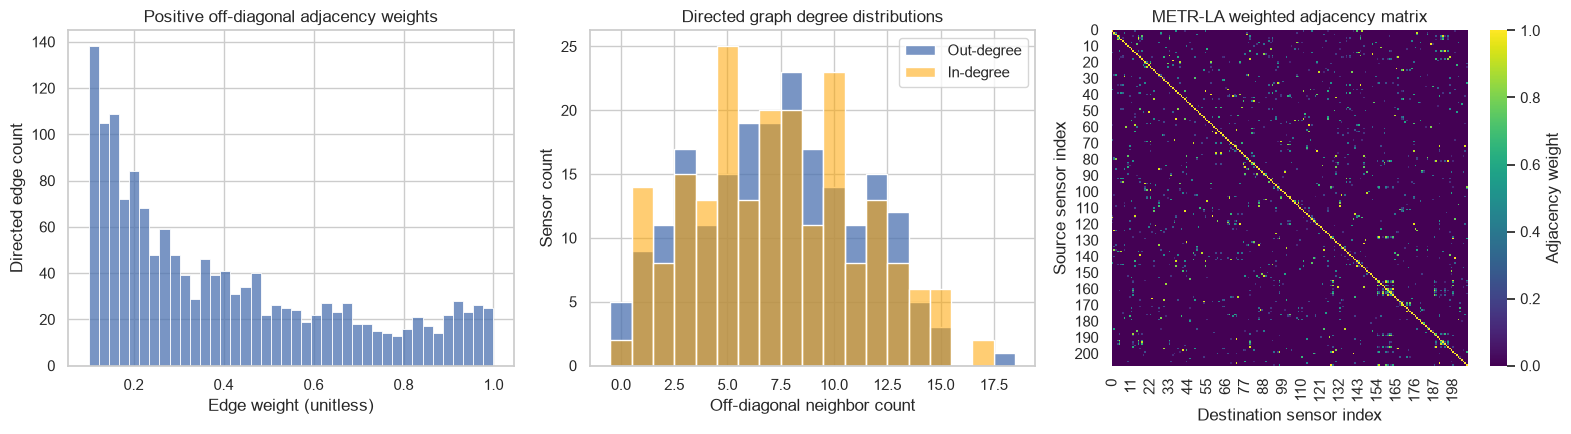

**What the charts show and why it matters.** The weight histogram shows the strength of the supplied connections, while the degree chart shows how many incoming and outgoing neighbours each sensor has. The heatmap is a visual map of the full adjacency matrix; its many dark cells show that the graph is sparse, meaning most sensor pairs are not directly connected. Because connections are weighted and direction-dependent, they provide a graph model with spatial information that an independent-sensor model does not use. This does not mean the graph model will necessarily forecast more accurately; the project will test whether the additional spatial information improves held-out forecasting performance. The verified sensor order can be used later, but every graph-aware data loader should still assert alignment to prevent silent sensor swaps.

In [10]:
out_degree = (off_diagonal > 0).sum(axis=1)
in_degree = (off_diagonal > 0).sum(axis=0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(positive_weights, bins=40, ax=axes[0])
axes[0].set(title='Positive off-diagonal adjacency weights', xlabel='Edge weight (unitless)', ylabel='Directed edge count')
sns.histplot(out_degree, discrete=True, ax=axes[1], label='Out-degree')
sns.histplot(in_degree, discrete=True, ax=axes[1], color='orange', alpha=0.55, label='In-degree')
axes[1].set(title='Directed graph degree distributions', xlabel='Off-diagonal neighbor count', ylabel='Sensor count')
axes[1].legend()
sns.heatmap(A, cmap='viridis', ax=axes[2], cbar_kws={'label': 'Adjacency weight'})
axes[2].set(title='METR-LA weighted adjacency matrix', xlabel='Destination sensor index', ylabel='Source sensor index')
plt.tight_layout()
plt.show()
display(Markdown(
    '**What the charts show and why it matters.** The weight histogram shows the strength of the supplied connections, while the degree chart shows how many incoming and outgoing neighbours each sensor has. '
    'The heatmap is a visual map of the full adjacency matrix; its many dark cells show that the graph is sparse, meaning most sensor pairs are not directly connected. '
    'Because connections are weighted and direction-dependent, they provide a graph model with spatial information that an independent-sensor model does not use. This does not mean the graph model will necessarily forecast more accurately; the project will test whether the additional spatial information improves held-out forecasting performance. The verified sensor order can be used later, but every graph-aware data loader should still assert alignment to prevent silent sensor swaps.'
))


## 5. Key findings, limitations, and implications

The final cell brings the main results together. Its text is generated from the values calculated above, so the conclusions remain tied to this exact dataset copy rather than being manually typed numbers.


In [11]:
display(Markdown(f'''
### Key findings

- **Dataset integrity:** {speeds.shape[0]:,} timestamps × {speeds.shape[1]} sensors, spanning {speeds.index.min()} to {speeds.index.max()}. Timestamps are unique, strictly increasing, and every interval is five minutes.
- **Missing and zero values:** {int(missing_by_sensor.sum()):,} explicit NaNs and {int(zero_by_sensor.sum()):,} exact zeros ({100 * zero_by_sensor.sum() / speeds.size:.3f}% of cells). All {speeds.shape[1]} sensors contain at least one zero; {int(all_sensor_zero_mask.sum()):,} timestamps are zero across every sensor, and the longest such run is {longest_true_run(all_sensor_zero_mask)} steps ({longest_true_run(all_sensor_zero_mask) * 5 / 60:.2f} hours). Zeros were not modified or interpreted as missing. Their uneven and synchronized runs require a documented policy in Task 03.
- **Traffic patterns:** speeds have a mean of {np.nanmean(values):.2f} mph and median of {np.nanmedian(values):.2f} mph, with clear hour-of-day and day-of-week variation plus substantial sensor heterogeneity. These patterns justify later time features and sensor-level error analysis, without using held-out future statistics during fitting.
- **Graph:** the trusted pickle contains a {A.shape[0]} × {A.shape[1]} weighted adjacency with {int(np.count_nonzero(off_diagonal)):,} directed off-diagonal edges, {int(np.count_nonzero(np.diag(A)))} self-loops, and {100 * np.count_nonzero(A) / A.size:.2f}% density. It is {'symmetric' if np.allclose(A, A.T) else 'asymmetric'}.
- **Alignment:** CSV sensor columns, pickle sensor list, pickle ID-to-index mapping, and the DCRNN `graph_sensor_ids.txt` reference match exactly in both membership and order. No reorder mapping is needed for these copies; later loaders should retain explicit assertions.

### Limitations and next-task implications

- File hashes identify the inspected local assets, but independent comparison with publisher-posted checksums is unavailable in the current local evidence. Provenance remains Zenodo record 5724362 plus the DCRNN sensor-ID reference.
- The dataset does not establish whether each zero is stopped traffic or a measurement/data-code issue. Task 03 must choose and test a scientifically defensible missing/zero policy without silently rewriting observations.
- Aggregated hourly/day-of-week summaries use the full series for EDA only. Any learned transforms or statistics must later be fitted on chronological training data only.
- Adjacency weights encode the supplied graph construction, not causal influence. Directionality, self-loops, and normalization must be documented when the ST-GNN is implemented.
- METR-LA lacks weather, incidents, events, and driver-level context, so later conclusions are limited to predictive associations in this historical network.
'''))



### Key findings

- **Dataset integrity:** 34,272 timestamps × 207 sensors, spanning 2012-03-01 00:00:00 to 2012-06-27 23:55:00. Timestamps are unique, strictly increasing, and every interval is five minutes.
- **Missing and zero values:** 0 explicit NaNs and 575,302 exact zeros (8.109% of cells). All 207 sensors contain at least one zero; 2,148 timestamps are zero across every sensor, and the longest such run is 381 steps (31.75 hours). Zeros were not modified or interpreted as missing. Their uneven and synchronized runs require a documented policy in Task 03.
- **Traffic patterns:** speeds have a mean of 53.72 mph and median of 62.44 mph, with clear hour-of-day and day-of-week variation plus substantial sensor heterogeneity. These patterns justify later time features and sensor-level error analysis, without using held-out future statistics during fitting.
- **Graph:** the trusted pickle contains a 207 × 207 weighted adjacency with 1,515 directed off-diagonal edges, 207 self-loops, and 4.02% density. It is asymmetric.
- **Alignment:** CSV sensor columns, pickle sensor list, pickle ID-to-index mapping, and the DCRNN `graph_sensor_ids.txt` reference match exactly in both membership and order. No reorder mapping is needed for these copies; later loaders should retain explicit assertions.

### Limitations and next-task implications

- File hashes identify the inspected local assets, but independent comparison with publisher-posted checksums is unavailable in the current local evidence. Provenance remains Zenodo record 5724362 plus the DCRNN sensor-ID reference.
- The dataset does not establish whether each zero is stopped traffic or a measurement/data-code issue. Task 03 must choose and test a scientifically defensible missing/zero policy without silently rewriting observations.
- Aggregated hourly/day-of-week summaries use the full series for EDA only. Any learned transforms or statistics must later be fitted on chronological training data only.
- Adjacency weights encode the supplied graph construction, not causal influence. Directionality, self-loops, and normalization must be documented when the ST-GNN is implemented.
- METR-LA lacks weather, incidents, events, and driver-level context, so later conclusions are limited to predictive associations in this historical network.
